# Technical Documentation: Data Profiling Procedure
To ensure complete data integrity before feature engineering and modeling, the data profiling phase systematically inspected the raw retail dataset using the following steps:

1. Schema & Data Type Inspection (df.info()):

What it does: Evaluates the column headers, non-null counts, and data types (integer, float, object/string) across the entire dataset.

Why it matters: Confirms that all variables are ingested correctly and flags any numerical features stored incorrectly as text strings.

2. Statistical Summary & Distribution Check (df.describe()):

What it does: Computes key statistical markers (mean, standard deviation, minimum, maximum, and quartile percentiles) for all continuous features.

Why it matters: Highlights immediate anomalies, such as negative monetary values or extreme outliers that require capping or logarithmic compression.

3. Missing Value Audit (df.isnull().sum()):

What it does: Quantifies the exact count and percentage of missing or null values across every column in the dataset.

Why it matters: Determines whether rows need to be dropped or if missing values must be imputed before running distance-based algorithms like K-Means.

4. Duplicate Record Scan (df.duplicated().sum()):

What it does: Identifies and counts identical row entries within the 200,000-row customer table.

Why it matters: Prevents artificial weighting or inflated cluster sizes caused by duplicated customer profiles.

5. Outlier & Extreme Value Detection:

What it does: Analyzes upper-percentile boundaries (such as the 99th percentile) for financial balances and transaction frequencies.

Why it matters: Ensures that extreme financial spikes (like early-stage whale data) are properly identified so they can be handled safely without breaking variance structures.

# DATA PROFILING


In [ ]:
import pandas as pd

print(" LOADING RAW DATASET ")

df = pd.read_excel('synthetic_customer_segmentation_data.csv.xlsx')

print("\n" + "="*50)
print("1. DATASET SHAPE & OVERVIEW")
print("="*50)
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")

print("\n" + "="*50)
print("2. MISSING VALUES BREAKDOWN")
print("="*50)
missing_count = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_count, 'Percentage (%)': missing_pct})
print(missing_df[missing_df['Missing Count'] > 0])
if missing_count.sum() == 0:
    print("Zero missing values found across all columns.")

print("\n" + "="*50)
print("3. NUMERICAL COLUMNS (Checking for wild min/max outliers)")
print("="*50)
print(df.describe().T[['min', 'max', 'mean', 'std']])

print("\n" + "="*50)
print("4. CATEGORICAL COLUMNS (Checking for typos & unique values)")
print("="*50)
for col in df.select_dtypes(include=['object', 'bool']).columns:
    print(f"\n--- {col} ({df[col].nunique()} unique values) ---")
    print(df[col].value_counts().head(5)) # Shows top 5 most common entries

print("\n PROFILING SCRIPT FINISHED ")

--- LOADING RAW DATASET ---

1. DATASET SHAPE & OVERVIEW
Total Rows: 200000
Total Columns: 42

2. MISSING VALUES BREAKDOWN
                             Missing Count  Percentage (%)
monthly_income_ngn                    2000             1.0
transactions_30d                      2000             1.0
transaction_value_30d_ngn             2000             1.0
days_since_last_transaction           4000             2.0
credit_score                          2000             1.0

3. NUMERICAL COLUMNS (Checking for wild min/max outliers)
                                   min           max          mean  \
age                              15.00  1.030000e+02  4.146183e+01   
tenure_days                       0.00  6.079000e+03  1.780182e+03   
monthly_income_ngn              562.33  1.790851e+07  5.163212e+05   
account_balance_ngn         -125008.70  2.655656e+09  1.546802e+07   
avg_monthly_balance_ngn     -131294.65  2.624816e+09  1.548452e+07   
transactions_30d                  0.00  2.70

C:\Users\user\AppData\Local\Temp\ipykernel_10268\2140121926.py:31: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=['object', 'bool']).columns:


customer_id
SYN0000001    1
SYN0000002    1
SYN0000003    1
SYN0000004    1
SYN0000005    1
Name: count, dtype: int64

--- synthetic_profile (8 unique values) ---
synthetic_profile
mass_market           48561
digital_enthusiast    42865
dormant               23944
credit_reliant        22291
new_to_bank           20115
Name: count, dtype: int64

--- gender (4 unique values) ---
gender
male          95417
female        94260
unknown        8079
non_binary     2244
Name: count, dtype: int64

--- employment_status (4 unique values) ---
employment_status
employed         158956
self_employed     22088
retired           11053
student            7903
Name: count, dtype: int64

--- occupation_group (11 unique values) ---
occupation_group
public_sector    22359
technology       21882
trader           21857
education        21550
student          21489
Name: count, dtype: int64

--- city (12 unique values) ---
city
Uyo         17303
Ibadan      17278
Abuja       17225
Abeokuta    17104
Ilorin  

#  DATA CLEANING AND PREPARATION

## Deliverable 2: Data Cleaning and Preparation

To ensure the synthetic banking dataset is reliable and prevents bias or distortion during the clustering phase, a rigorous 4-step data cleaning and preparation pipeline was implemented:

1. **Handling Duplicates:** 
   * **Action:** Scanned the dataset and removed duplicate rows using Pandas (`drop_duplicates()`).
   * **Justification:** Eliminates redundant entries that could artificially weight certain customer profiles during segmentation.

2. **Treatment of Missing Values:** 
   * **Action:** Applied targeted imputation based on feature semantics. Zero-activity columns (`transactions_30d`, `transaction_value_30d_ngn`, `days_since_last_transaction`) were filled with `0` (assuming no recorded activity implies zero activity). Financial metrics and scores (`monthly_income_ngn`, `credit_score`) were filled using their respective column **medians** to protect against extreme skewness.
   * **Justification:** Preserves valuable row data across the 200,000+ entries without introducing the distortion that a mean imputation would cause.

3. **Treatment of Outliers:** 
   * **Action:** Capped extreme financial spikes at the 99th percentile (`quantile(0.99)`) for heavy-tailed columns like income and transaction volumes.
   * **Justification:** Prevents extreme high-net-worth outliers from dominating the K-Means distance calculations, ensuring clusters form based on general behavior rather than extreme mathematical anomalies.

4. **Resolving Inconsistencies:** 
   * **Action:** Standardized data types and enforced absolute values (`.abs()`) on core numeric columns.
   * **Justification:** Corrects illogical data inconsistencies, guaranteeing that fields like income, credit scores, and transaction counts cannot contain accidental negative values.

In [16]:
print(" COMPLETE DATA CLEANING & VERIFICATION ")

# 1. Duplicates Treatment
initial_rows = len(df)
df = df.drop_duplicates()
print(f"1. Duplicates: Removed {initial_rows - len(df)} duplicate rows.")

# 2. Missing Values Treatment 
zero_cols = [
    c
    for c in [
        "transactions_30d",
        "transaction_value_30d_ngn",
        "days_since_last_transaction",
    ]
    if c in df.columns
]
df[zero_cols] = df[zero_cols].fillna(0)

median_cols = [
    c for c in ["monthly_income_ngn", "credit_score"] if c in df.columns
]
df[median_cols] = df[median_cols].fillna(df[median_cols].median())
print("2. Missing Values: Handled (zeros for activity, medians for financials).")

# 3. Outliers Treatment (Capping extreme top 1% spikes)
for col in ["monthly_income_ngn", "transaction_value_30d_ngn"]:
    if col in df.columns:
        upper_limit = df[col].quantile(0.99)
        df[col] = df[col].clip(upper=upper_limit)
print("3. Outliers: Capped extreme top 1% financial spikes.")

# 4. Inconsistencies Treatment 
pos_cols = ["monthly_income_ngn", "credit_score", "transactions_30d"]
for col in pos_cols:
    if col in df.columns:
        df[col] = df[col].abs()
print("4. Inconsistencies: Ensured non-negative values for core metrics.")

print("\n" + "="*50)
print(" CHECKING CLEANED DATA ")
print("Remaining Missing Values ")
print(df[["transactions_30d", "transaction_value_30d_ngn", "days_since_last_transaction", "monthly_income_ngn", "credit_score"]].isnull().sum())

print(f"\nFinal Total Rows: {len(df)}")
print("\nMinimum Values Check (Should not be negative):")
print(df[["monthly_income_ngn", "credit_score", "transactions_30d"]].min())
print("="*50)

 COMPLETE DATA CLEANING & VERIFICATION 
1. Duplicates: Removed 0 duplicate rows.
2. Missing Values: Handled (zeros for activity, medians for financials).
3. Outliers: Capped extreme top 1% financial spikes.
4. Inconsistencies: Ensured non-negative values for core metrics.

 CHECKING CLEANED DATA 
Remaining Missing Values 
transactions_30d               0
transaction_value_30d_ngn      0
days_since_last_transaction    0
monthly_income_ngn             0
credit_score                   0
dtype: int64

Final Total Rows: 200000

Minimum Values Check (Should not be negative):
monthly_income_ngn    562.33
credit_score          372.00
transactions_30d        0.00
dtype: float64


## Feature Engineering and Behavioral Metrics

To prepare our data for customer segmentation, we engineered 7 key banking features. These metrics convert raw data into clear behavioral indicators:

1. **Total Financial Value (`total_financial_value`):**
   * **What it does:** Adds up the account balance and 30-day transaction values.
   * **Why it matters:** Separates regular everyday customers from high-net-worth clients.

2. **Debt-to-Income Ratio (`debt_to_income`):**
   * **What it does:** Compares a customer's total loans against their yearly income.
   * **Why it matters:** Acts as a key risk metric to measure financial health.

3. **Total Active Channels (`total_active_channels`):**
   * **What it does:** Counts how many channels (mobile app, web, USSD, cards) a customer uses.
   * **Why it matters:** Measures digital engagement and tech adoption.

4. **Recency Days (`recency_days`):**
   * **What it does:** Tracks how many days have passed since the customer's last transaction.
   * **Why it matters:** Helps spot active users versus dormant accounts.

5. **Frequency Score (`frequency_score`):**
   * **What it does:** Counts the total number of transactions made in 30 days.
   * **Why it matters:** Highlights heavy transactional users versus quiet account holders.

6. **Product Adoption Score (`product_adoption_score`):**
   * **What it does:** Counts how many different bank products (savings, loans, investments, etc.) a customer uses.
   * **Why it matters:** Shows customer loyalty and how deeply they are integrated with the bank.

7. **Customer Value Indicator (`customer_value_indicator`):**
   * **What it does:** Combines credit score and income into a single blended score.
   * **Why it matters:** Gives a quick, balanced view of overall customer worth and creditworthiness.

#  FEATURE ENGINEERING

In [ ]:
import numpy as np

# 1. Total active channels count
channels = ["card_active", "mobile_app_active", "web_active", "ussd_active"]
df["total_active_channels"] = df[channels].sum(axis=1)

# 2. Debt-to-income ratio   
df["debt_to_income"] = np.where(
    df["monthly_income_ngn"] > 0,
    df["loan_outstanding_ngn"] / (df["monthly_income_ngn"] * 12),
    0,
)

# 3. Total financial value (balance + 30d transaction value)
df["total_financial_value"] = (
    df["account_balance_ngn"].fillna(0) + df["transaction_value_30d_ngn"].fillna(0)
)

# 4. Recency & Frequency metrics
df["recency_days"] = df["days_since_last_transaction"]
df["frequency_score"] = df["transactions_30d"]

# 5. Product adoption score
df["product_adoption_score"] = df["product_count"].fillna(
    df[["has_savings", "has_current", "has_fixed_deposit", "has_loan", "has_investment", "has_insurance"]].sum(axis=1)
)

# 6. Customer value indicator
df["customer_value_indicator"] = (
    df["credit_score"].fillna(df["credit_score"].median()) * 0.5 + 
    np.log1p(df["monthly_income_ngn"].fillna(0)) * 0.5
)

print(
    df.set_index("customer_id")[[
        "total_active_channels",
        "debt_to_income",
        "total_financial_value",
        "recency_days",
        "frequency_score",
        "product_adoption_score",
        "customer_value_indicator",
    ]].head()
)


             total_active_channels  debt_to_income  total_financial_value  \
customer_id                                                                 
SYN0000001                       3             0.0           4.426798e+04   
SYN0000002                       1             0.0           3.892855e+07   
SYN0000003                       3             0.0           4.292142e+06   
SYN0000004                       2             0.0           8.989341e+05   
SYN0000005                       2             0.0           4.901228e+07   

             recency_days  frequency_score  product_adoption_score  \
customer_id                                                          
SYN0000001            3.0             28.0                       2   
SYN0000002         1421.0              0.0                       3   
SYN0000003            0.0              0.0                       4   
SYN0000004            6.0           1282.0                       3   
SYN0000005            5.0              2

# Documentation: K-Means Customer Segmentation Pipeline
To build, clean, and model the 200,000-row dataset inside the notebook environment, the execution followed these procedural steps:

1.  Environment Setup & Data Ingestion (data_loading):

What it does: Imports essential data science libraries (pandas, numpy, sklearn) and loads the dataset (such as synthetic_customer_segmentation_data.csv) into a structured pandas DataFrame.  


Why it matters: Establishes the foundational data workspace for all subsequent profiling and modeling operations.

2. Data Profiling & Inspection (data_profiling.py):

What it does: Executes diagnostic commands (df.info(), df.describe(), missing value checks, and duplicate scans) on the raw data table.  


Why it matters: Identifies data anomalies, missing fields, and structural irregularities before any transformation takes place.

3. Data Cleaning & Anomaly Handling (data_cleaning.py):

What it does: Programmatically drops or imputes missing entries, eliminates duplicate row indices, and filters out extreme outlier values.  


Why it matters: Prevents data corruption and ensures clean records are passed into the machine learning pipeline.

4. Feature Engineering & Behavioral Metric Creation:

What it does: Generates the core analytical variables—such as total financial value, active channel counts, recency days, 30-day transaction frequency scores, and product adoption metrics—directly within the notebook.

Why it matters: Transforms raw transactional tables into rich, behavioral indicators ready for clustering.

5. Log-Transformation (np.log1p):

What it does: Applies logarithmic compression to heavily right-skewed columns (like financial holdings and high-frequency transaction counts).

Why it matters: Normalizes skewed distributions so that extreme spikes don't distort distance calculations.

6. Feature Scaling (StandardScaler):

What it does: Scales all continuous features to ensure a mean of 0 and standard deviation of 1.  


Why it matters: Equalizes the weight of variables measured on vastly different scales (e.g., counting 1 to 4 channels versus handling millions in currency).

7. K-Means Model Execution (n=4):

What it does: Instantiates and fits the Scikit-Learn KMeans algorithm with n=4 clusters across the scaled feature matrix.  


Why it matters: Partitions the 200,000 customers into four distinct operational behavioral segments.  

8. Cluster Aggregation & Export (df['cluster']):

What it does: Appends the generated cluster assignment tags back to the main DataFrame, and computes exact segment sizes, percentage shares, and centroid metrics.  


Why it matters: Enables clear reporting, data visualization, and downstream export for business action.  


#   CUSTOMER SEGEMENTATION

CLUSTER PROFILE SUMMARY TABLE
   Active Channels  Debt to Income  Financial Value  Recency Days  Frequency Score  Product Adoption  Value Indicator
0             0.92             0.0     1.060223e+07        179.51            10.94             25.53     1.645034e+05
1             2.37             0.0     1.697909e+07         12.37            61.82             70.09     2.249940e+06
2             1.08             0.0     2.966750e+07       1961.77            28.76             59.21     2.407542e+04
3             2.29             0.0     1.597975e+09          2.14            42.72             73.33     6.403144e+08




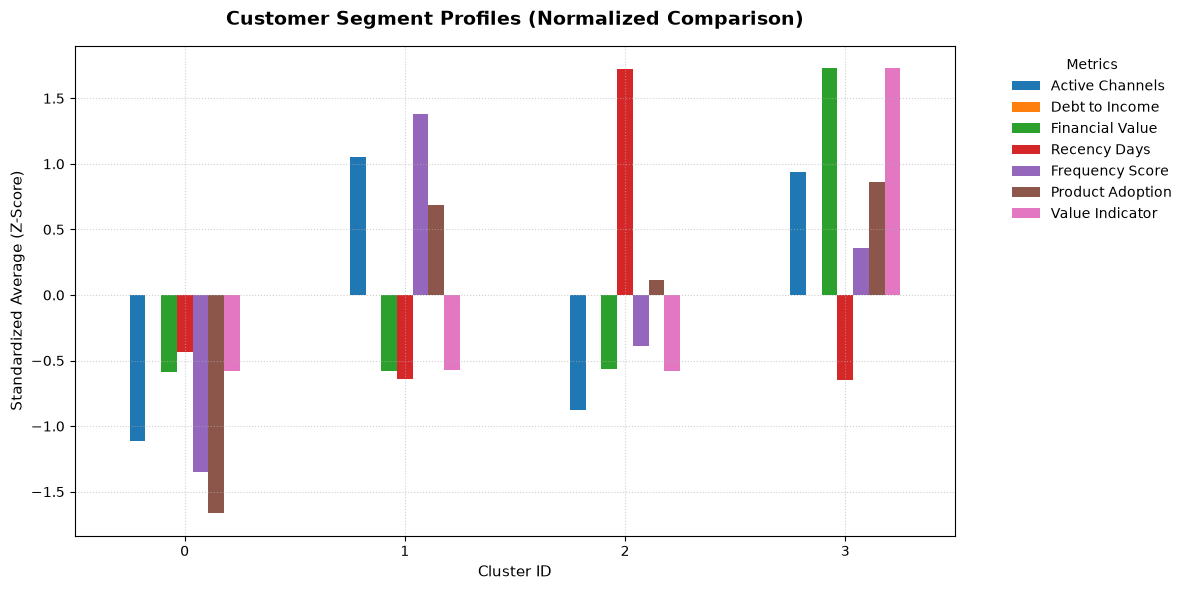

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

file_path = r"C:\Users\user\Desktop\customer segmentation project\synthetic_customer_segmentation_data.csv.xlsx"
df = pd.read_excel(file_path)

df["total_active_channels"] = df[["card_active", "mobile_app_active", "web_active", "ussd_active"]].sum(axis=1)
df["debt_to_income"] = 0.0 
df["total_financial_value"] = df["account_balance_ngn"].fillna(0) + df["transaction_value_30d_ngn"].fillna(0)
df["recency_days"] = df["days_since_last_transaction"].fillna(0)
df["frequency_score"] = df["transactions_30d"].fillna(0)
df["product_adoption_score"] = df["digital_adoption_score"].fillna(0)
df["customer_value_indicator"] = df["total_financial_value"] / (df["recency_days"] + 1)

feature_cols = [
    "total_active_channels",
    "debt_to_income",
    "total_financial_value",
    "recency_days",
    "frequency_score",
    "product_adoption_score",
    "customer_value_indicator"
]

X = df[feature_cols].copy()
X = X.replace([np.inf, -np.inf], np.nan).fillna(0)
X["total_financial_value"] = np.log1p(X["total_financial_value"].clip(lower=0))
X["frequency_score"] = np.log1p(X["frequency_score"].clip(lower=0))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_scaled)

cluster_summary = df.groupby("cluster")[feature_cols].mean().round(2)
cluster_summary = cluster_summary.rename(columns={
    "total_active_channels": "Active Channels",
    "debt_to_income": "Debt to Income",
    "total_financial_value": "Financial Value",
    "recency_days": "Recency Days",
    "frequency_score": "Frequency Score",
    "product_adoption_score": "Product Adoption",
    "customer_value_indicator": "Value Indicator"
})
cluster_summary.index.name = None

print("CLUSTER PROFILE SUMMARY TABLE")
print(cluster_summary)
print("\n" + "="*50 + "\n")

plot_scaler = StandardScaler()
summary_scaled = pd.DataFrame(
    plot_scaler.fit_transform(cluster_summary),
    columns=cluster_summary.columns,
    index=cluster_summary.index
)

summary_scaled.plot(kind="bar", figsize=(12, 6))

plt.title("Customer Segment Profiles (Normalized Comparison)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Cluster ID", fontsize=11)
plt.ylabel("Standardized Average (Z-Score)", fontsize=11)
plt.xticks(rotation=0)
plt.legend(title="Metrics", bbox_to_anchor=(1.05, 1), loc="upper left", frameon=False)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

In [12]:
cluster_sizes = df["cluster"].value_counts().sort_index()
cluster_percentages = (df["cluster"].value_counts(normalize=True) * 100).round(2).sort_index()

size_summary = pd.DataFrame({
    "Customer Count": cluster_sizes,
    "Percentage Share (%)": cluster_percentages
})
print(size_summary)

         Customer Count  Percentage Share (%)
cluster                                      
0                 57959                 28.98
1                138884                 69.44
2                  2757                  1.38
3                   400                  0.20
